# PA 2025 Unet implementation on TM 2025-26 synthetic data

Most of this document is a take directly from my PA "Astronomical Adaptive Optics Point Spread Function Reconstruction with Machine Learning Algorithms" (HES-SO master, 1001, Lausanne) with some minor adjustments to make it work with PyTorch.

## Inputs

In [1]:
outputDir = "output_ML/"
history_path = outputDir + "/history.h5"
inputDir = "output_prep/"

stabilisation_delay = 100

rng_SEED = 42
train_split = 0.8

GPU = True
MULTIGPU = True

SMALL_SIZE = 20
MEDIUM_SIZE = 20
BIGGER_SIZE = 25

In [2]:
%matplotlib widget
import os
os.environ["KERAS_BACKEND"] = "torch"
# os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2" # https://discuss.pytorch.org/t/limit-process-to-single-gpu/55806/2
import copy
import torch
from torch.optim import SGD
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score
import keras
import h5py
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm  # tqdm: merci Jonathan!
import TM26_unet as unet
import myfunctions
print(torch.__version__)
print(keras.__version__)
print(torch.cuda.is_available())

2.12.0+cu130
3.14.1
True


## WFSx, WSFy

In [ ]:
# TODO: make size dynamic
# image_size = (80, 80)

# WFS_x = np.zeros((35000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((35000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     # print(tempData[0].shape)
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape= [80, 80])
# with h5py.File(inputDir+"ao_WFSy_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
# x_train = np.stack((WFS_x, WFS_y), axis=1)
# del WFS_x, WFS_y


# WFS_x = np.zeros((10000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((10000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# with h5py.File(inputDir+"ao_WFSy_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# x_val = np.stack((WFS_x, WFS_y), axis=1)
# del WFS_x, WFS_y

# with h5py.File(inputDir+"ao_ipsf_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_train = temp[key[0]][()][:]
# with h5py.File(inputDir+"ao_ipsf_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_val = temp[key[0]][()][:]


# print(f"x_train shape: {x_train.shape}")
# print(f"y_train shape: {y_train.shape}")
# print(f"x_val shape: {x_val.shape}")
# print(f"y_val shape: {y_val.shape}")


# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
# model = unet.build_unet(input_shape=(80, 80, 2), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy


x_train shape: (35000, 2, 80, 80)
y_train shape: (35000, 80, 80)
x_val shape: (10000, 2, 80, 80)
y_val shape: (10000, 80, 80)


## Lightfield

In [ ]:
# with h5py.File(inputDir+"ao_lightfield_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     # print(key)
#     x_train = temp[key[0]][()]
# with h5py.File(inputDir+"ao_lightfield_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     x_val = temp[key[0]][()]

# image_size = (x_train.shape[1], x_val.shape[2])
# print(image_size)

# print(f"x_train shape: {x_train.shape}")
# print(f"x_val shape: {x_val.shape}")

# with h5py.File(inputDir+"ao_ipsf_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     y_train = np.zeros((tempData.shape[0], 270, 270))
#     for i in range(tempData.shape[0]):
#         y_train[i] = myfunctions.pixel_adder(tempData[i], final_shape=[270, 270])
# with h5py.File(inputDir+"ao_ipsf_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     y_val = np.zeros((tempData.shape[0], 270, 270))
#     for i in range(tempData.shape[0]):
#         y_val[i] = myfunctions.pixel_adder(tempData[i], final_shape=[270, 270])

# print(f"y_train shape: {y_train.shape}")
# print(f"y_val shape: {y_val.shape}")

# plt.close(0)
# plt.figure(0)
# plt.imshow(x_train[0])

# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
# model = unet.build_unet(input_shape=(*image_size, 1), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy


(270, 270)
x_train shape: (35000, 270, 270)
x_val shape: (10000, 270, 270)
y_train shape: (35000, 270, 270)
y_val shape: (10000, 270, 270)


## WFSx, WFSy, intensity map

In [ ]:
# image_size = (80, 80)

# WFS_x = np.zeros((35000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((35000, *image_size))
# intensity = np.zeros((35000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     # print(tempData[0].shape)
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape= [80, 80])
# with h5py.File(inputDir+"ao_WFSy_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
# with h5py.File(inputDir+"intensity_map_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     for i in range(tempData.shape[0]):
#         intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])

# x_train = np.stack((WFS_x, WFS_y, intensity), axis=1)
# del WFS_x, WFS_y, intensity


# WFS_x = np.zeros((10000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((10000, *image_size))
# intensity = np.zeros((10000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# with h5py.File(inputDir+"ao_WFSy_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# with h5py.File(inputDir+"intensity_map_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# x_val = np.stack((WFS_x, WFS_y, intensity), axis=1)
# del WFS_x, WFS_y, intensity

# with h5py.File(inputDir+"ao_ipsf_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_train = temp[key[0]][()][:]
# with h5py.File(inputDir+"ao_ipsf_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_val = temp[key[0]][()][:]


# print(f"x_train shape: {x_train.shape}")
# print(f"y_train shape: {y_train.shape}")
# print(f"x_val shape: {x_val.shape}")
# print(f"y_val shape: {y_val.shape}")

# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
# model = unet.build_unet(input_shape=(80, 80, 3), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx, WFSy and intensity


x_train shape: (35000, 3, 80, 80)
y_train shape: (35000, 80, 80)
x_val shape: (10000, 3, 80, 80)
y_val shape: (10000, 80, 80)


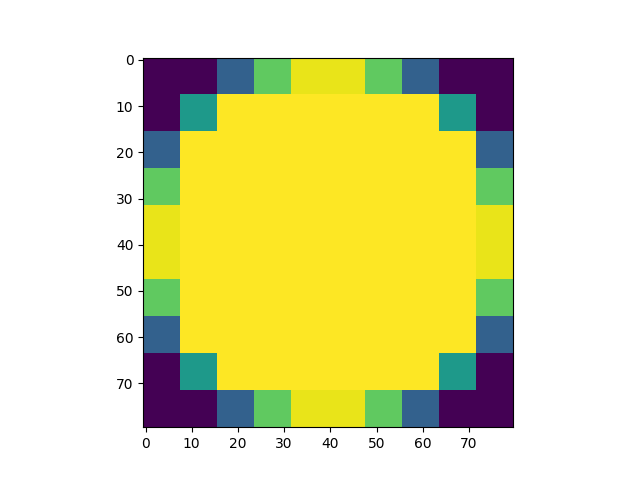

In [7]:
plt.close(0)
plt.figure(0)
plt.imshow(x_train[0,2])

## WFSx, WFSy, DM

In [ ]:
# image_size = (80, 80)

# WFS_x = np.zeros((35000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((35000, *image_size))
# intensity = np.zeros((35000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     # print(tempData[0].shape)
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape= [80, 80])
# with h5py.File(inputDir+"ao_WFSy_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
# with h5py.File(inputDir+"ao_DM_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()][:]
#     for i in range(tempData.shape[0]):
#         intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])

# x_train = np.stack((WFS_x, WFS_y, intensity), axis=1)
# del WFS_x, WFS_y, intensity


# WFS_x = np.zeros((10000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
# WFS_y = np.zeros((10000, *image_size))
# intensity = np.zeros((10000, *image_size))
# with h5py.File(inputDir+"ao_WFSx_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# with h5py.File(inputDir+"ao_WFSy_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# with h5py.File(inputDir+"ao_DM_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempData = temp[key[0]][()]
#     for i in range(tempData.shape[0]):
#         intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
# x_val = np.stack((WFS_x, WFS_y, intensity), axis=1)
# del WFS_x, WFS_y, DM

# with h5py.File(inputDir+"ao_ipsf_train_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_train = temp[key[0]][()][:]
# with h5py.File(inputDir+"ao_ipsf_val_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     y_val = temp[key[0]][()][:]


# print(f"x_train shape: {x_train.shape}")
# print(f"y_train shape: {y_train.shape}")
# print(f"x_val shape: {x_val.shape}")
# print(f"y_val shape: {y_val.shape}")

# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
# model = unet.build_unet(input_shape=(80, 80, 3), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx, WFSy and intensity


x_train shape: (35000, 3, 80, 80)
y_train shape: (35000, 80, 80)
x_val shape: (10000, 3, 80, 80)
y_val shape: (10000, 80, 80)


## WFSx, WFSy, intensity map, DM

In [3]:
image_size = (80, 80)

WFS_x = np.zeros((35000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
WFS_y = np.zeros((35000, *image_size))
DM = np.zeros((35000, *image_size))
intensity = np.zeros((35000, *image_size))
with h5py.File(inputDir+"ao_WFSx_train_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    # print(tempData[0].shape)
    for i in range(tempData.shape[0]):
        WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape= [80, 80])
with h5py.File(inputDir+"ao_WFSy_train_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
with h5py.File(inputDir+"ao_DM_train_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        DM[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
with h5py.File(inputDir+"intensity_map_train_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()]
    for i in range(tempData.shape[0]):
        intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])

x_train = np.stack((WFS_x, WFS_y, DM, intensity), axis=1)
del WFS_x, WFS_y, DM, intensity


WFS_x = np.zeros((10000, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
WFS_y = np.zeros((10000, *image_size))
DM = np.zeros((10000, *image_size))
intensity = np.zeros((10000, *image_size))
with h5py.File(inputDir+"ao_WFSx_val_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()]
    for i in range(tempData.shape[0]):
        WFS_x[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
with h5py.File(inputDir+"ao_WFSy_val_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()]
    for i in range(tempData.shape[0]):
        WFS_y[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80, 80])
with h5py.File(inputDir+"ao_DM_val_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        DM[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
with h5py.File(inputDir+"intensity_map_val_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        intensity[i] = myfunctions.pixel_adder(tempData[i], final_shape = [80,80])
x_val = np.stack((WFS_x, WFS_y, DM, intensity), axis=1)
del WFS_x, WFS_y, DM, intensity

with h5py.File(inputDir+"ao_ipsf_train_1.h5", 'r') as temp:
    key = list(temp.keys())
    y_train = temp[key[0]][()][:]
with h5py.File(inputDir+"ao_ipsf_val_1.h5", 'r') as temp:
    key = list(temp.keys())
    y_val = temp[key[0]][()][:]


print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_val shape: {x_val.shape}")
print(f"y_val shape: {y_val.shape}")

device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
model = unet.build_unet(input_shape=(80, 80, 4), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx, WFSy and intensity


x_train shape: (35000, 4, 80, 80)
y_train shape: (35000, 80, 80)
x_val shape: (10000, 4, 80, 80)
y_val shape: (10000, 80, 80)


## WFSx, WFSy, intensity map, DM -> OTF

## Unet

In [4]:
if torch.cuda.device_count() > 1 and MULTIGPU:
    model = torch.nn.DataParallel(model)

# TODO: à revoir
weight_path = outputDir+"{}_weights.best.pth".format("cxr_reg")


# Convert numpy arrays to torch tensors
# TODO: Evaluate pertinence of float32

x_train_tens = torch.tensor(x_train, dtype=torch.float32)/x_train.max()
x_val_tens = torch.tensor(x_val, dtype=torch.float32)/x_train.max()
y_train_tens = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)/y_train.max()
y_val_tens = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)/y_train.max()

print(f"x_train_tens shape {x_train_tens.shape}")
print(f"y_train_tens shape {y_train_tens.shape}")
print(f"x_val_tens shape {x_val_tens.shape}")
print(f"y_val_tens shape {y_val_tens.shape}")

with open(outputDir + "max_val.txt", "w") as f:
    f.write(f"x_train.max(): {x_train.max()}\n")
    f.write(f"y_train.max(): {y_train.max()}\n")

# Define batch size depending on device
batch_size = 800 if device.type == "cuda" else 12

x_train_tens shape torch.Size([35000, 4, 80, 80])
y_train_tens shape torch.Size([35000, 1, 80, 80])
x_val_tens shape torch.Size([10000, 4, 80, 80])
y_val_tens shape torch.Size([10000, 1, 80, 80])


## Dataloader

Shuffle = True for now in order to predict iPSFs. The temporality does not matter yet.

In [5]:
train_loader = DataLoader(TensorDataset(x_train_tens, y_train_tens), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val_tens, y_val_tens), batch_size=batch_size, shuffle=False)

for x_batch, y_batch in train_loader:
    print("x_batch shape:", x_batch.shape)  # should be [batch_size, 2, 270, 270]
    print("y_batch shape:", y_batch.shape)  # should be [batch_size, 1, 270, 270] or [batch_size, 270, 270]
    break

x_batch shape: torch.Size([800, 4, 80, 80])
y_batch shape: torch.Size([800, 1, 80, 80])


## Criterion and opti.

In [6]:
optimizer = SGD(model.parameters(), lr=0.001, momentum=0.9)
min_lr = 1e-7
scheduler = ReduceLROnPlateau(
    optimizer,
    mode='min',          # val_loss should decrease
    factor=0.1,          # reduce LR by 10x when stuck
    patience=5,          # wait 5 epochs with no improvement
    threshold=1e-5,      # minimum change to count as improvement
    threshold_mode='rel',# relative threshold (default)
    cooldown=0,          # no cooldown (fine for most cases)
    min_lr=min_lr,      # lower bound on LR
    eps=1e-8,            # minimal LR change (default)
)
criterion = unet.mse_loss

with open(outputDir + "ML_setup.txt", "w") as f:
    f.write(f"lr: {optimizer.param_groups[0]['lr']}\n")
    f.write(f"momentum: {optimizer.param_groups[0]['momentum']}\n")
    f.write(f"weight_decay: {optimizer.param_groups[0]['weight_decay']}\n")
    f.write(f"mode: {scheduler.mode}\n")
    f.write(f"factor: {scheduler.factor}\n")
    f.write(f"patience: {scheduler.patience}\n")
    f.write(f"threshold: {scheduler.threshold}\n")
    f.write(f"threshold_mode: {scheduler.threshold_mode}\n")
    f.write(f"cooldown: {scheduler.cooldown}\n")
    f.write(f"min_lr: {min_lr}\n")
    f.write(f"eps: {scheduler.eps}\n")

## Epoch helper

In [7]:
def run_epoch(model, loader, optimizer=None, phase="Train", epoch=0, num_epochs=1):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    running_loss = 0.0
    running_acc = 0.0

    pbar = tqdm(
        loader,
        desc=f"{phase} {epoch + 1}/{num_epochs}",
        leave=False
    )

    for inputs, targets in pbar:
        inputs = inputs.to(device)
        targets = targets.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            outputs = model(inputs)
            loss = criterion(targets, outputs)

            if is_training:
                loss.backward()
                optimizer.step()

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        acc = (preds == targets).float().mean().item()

        running_loss += loss.item() * inputs.size(0)
        running_acc += acc * inputs.size(0)

        # Update the loading bar with current batch values
        pbar.set_postfix(
            loss=f"{loss.item():.6f}",
            acc=f"{acc:.6f}"
        )

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = running_acc / len(loader.dataset)

    return epoch_loss, epoch_acc

## Training param

In [8]:
num_epochs = 2
early_stopping_patience = 15
best_val_loss = np.inf
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    "loss": [],
    "val_loss": [],
    "binary_accuracy": [],
    "val_binary_accuracy": [],
    "auc": [],
    "val_auc": []
}

In [9]:
for epoch in range(num_epochs):
    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer=optimizer,
        phase="Train",
        epoch=epoch,
        num_epochs=num_epochs
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader,
        optimizer=None,
        phase="Val",
        epoch=epoch,
        num_epochs=num_epochs
    )

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["binary_accuracy"].append(train_acc)
    history["val_binary_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs} - "
        f"loss: {train_loss:.6f} - val_loss: {val_loss:.6f} - "
        f"acc: {train_acc:.6f} - val_acc: {val_acc:.6f}"
    )

    # Update learning rate based on validation loss
    scheduler.step(val_loss)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), weight_path)
        print(f"Saved best model to {weight_path}")
    else:
        epochs_no_improve += 1

    # Stop training early if validation loss does not improve
    if epochs_no_improve >= early_stopping_patience:
        print("Early stopping triggered")
        break

model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), outputDir + "/model.weights.pth")

Train 1/2:   0%|          | 0/44 [00:00<?, ?it/s]

KeyboardInterrupt: 

## Output

[0.023516267697832414, 0.005064972812256643]


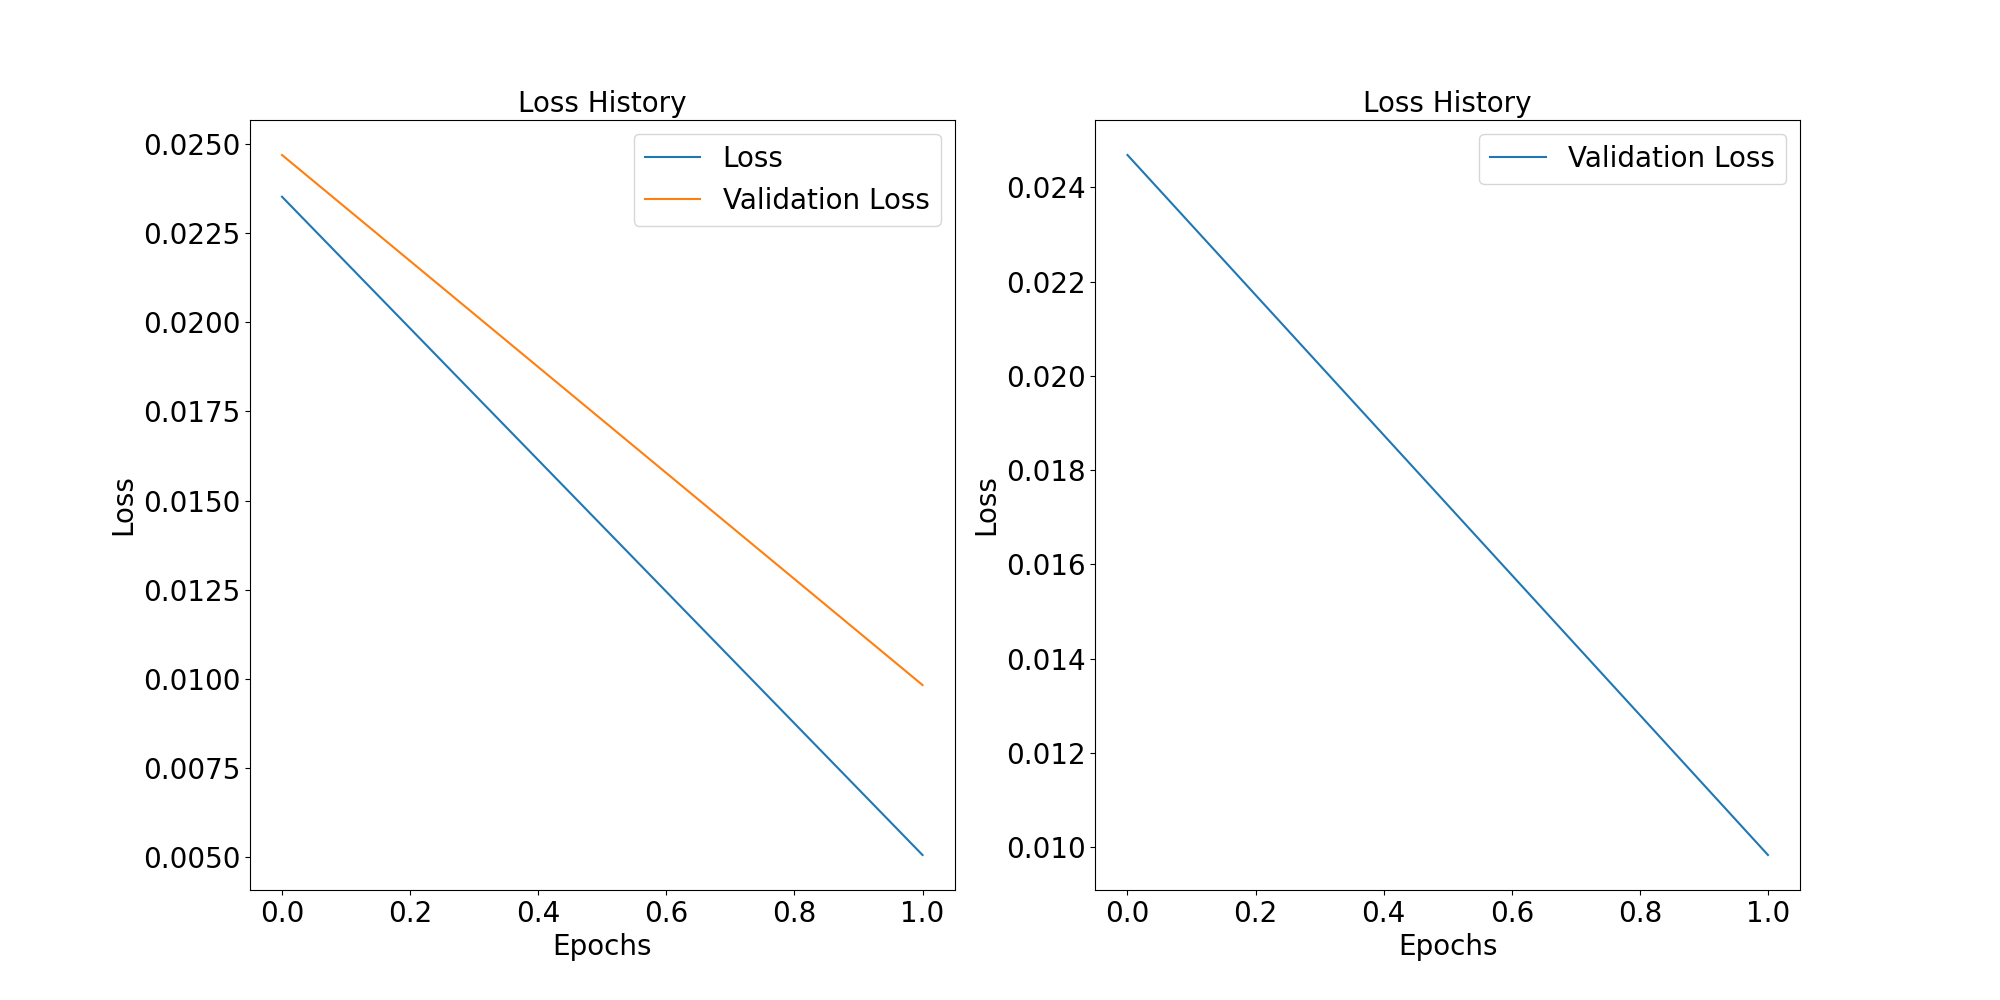

In [14]:
# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
# model = unet.build_unet(input_shape=(80,80, 2), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy

# Load the model weights

# model = torch.load('output_ML/model.weights.pth', weights_only=True)

# model.eval()

print(history["loss"])

# Plot loss and accuracy history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

ax1.plot(history["loss"], "-", label="Loss")
ax1.plot(history["val_loss"], "-", label="Validation Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.set_title("Loss History")
ax1.legend()

ax2.plot(np.array(history["val_loss"]), "-", label="Validation Loss")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Loss")
ax2.set_title("Loss History")
ax2.legend()

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=SMALL_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

plt.savefig(outputDir + "/loss.png")


In [ ]:
torch.cuda.empty_cache()

: 